# Universal Studios Reviews: Text Visualization Lab Activity
**Name:** Gbert O. Pilapil
**Date:**  10/27/2026
**Dataset Link:** https://www.kaggle.com/datasets/dwiknrd/reviewuniversalstudio

### Running on Google Colab
Just click **Runtime > Run all**. The dataset is downloaded automatically from Kaggle (public, no login needed). To use your own copy instead, upload `universal_studio_branches.csv` via the Files panel before running.

In [ ]:
# Colab setup: make sure every library is available (most are preinstalled on Colab)
%pip install -q wordcloud kagglehub nltk networkx scikit-learn

In [11]:
# STEP 0. Set-up. Importing Libraries.
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import nltk
from nltk.stem import WordNetLemmatizer
from collections import Counter
from wordcloud import WordCloud
from sklearn.feature_extraction.text import (ENGLISH_STOP_WORDS,
                                             CountVectorizer, TfidfVectorizer)

nltk.download(["wordnet", "omw-1.4"], quiet=True)

try:                                   # show tables nicely in Colab/Jupyter
    from IPython.display import display
except ImportError:
    display = print

# One color scheme for the whole notebook (colorblind-friendly Okabe-Ito colors)
BRANCH_COLORS = {"Florida": "#0072B2", "Singapore": "#E69F00", "Japan": "#CC79A7"}
SENT_COLORS = {"positive": "#2a9d8f", "neutral": "#adb5bd", "negative": "#e76f51"}
BRANCHES = ["Florida", "Singapore", "Japan"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "figure.dpi": 100})
pd.set_option("display.max_colwidth", 120)

print("Libraries loaded successfully!")

Libraries loaded successfully!


## 1. Define the Question

**Main question:**  What can become a bad experience when visiting Universal Studios? And what should each park fix first based on the reviews.

**Sub-question 1:**  Do visitors complain about different things at Universal Studios Florida, Singapore, and Japan?

**Sub-question 2:**  How did visitor complaints change over time, especially before and after the COVID-19 park closures?

## 2. Collect and Describe the Data

| Item | Description |
|---|---|
| Source | Kaggle, "Reviews of Universal Studios" by dwiknrd (https://www.kaggle.com/datasets/dwiknrd/reviewuniversalstudio). Reviews were originally posted on TripAdvisor. |
| Number of documents | 50,904 reviews in the raw file. After removing 45 exact duplicates: **50,859 reviews** (each review is one document) across 3 branches: Florida (30,587), Singapore (15,743), Japan (4,529). About 6 million words in total. |
| Time period | October 24, 2002 to May 30, 2021 (most reviews are from 2012 to 2019) |
| Columns | `reviewer` (account name), `rating` (1 to 5 stars), `written_date` (date posted), `title` (review title), `review_text` (full review), `branch` (Universal Studios Florida, Singapore, or Japan) |

**Ethical considerations (privacy, anonymization, terms of use):**
- **Privacy:** The reviews are public posts on TripAdvisor, but the `reviewer` column contains account names that could identify people. This column was dropped before analysis, and no usernames are shown in any chart or example.
- **Anonymization:** Example reviews shown in this notebook (such as KWIC lines) are short excerpts only, with no names attached. Keywords for KWIC were picked so the excerpts do not show health or family details about reviewers.
- **Terms of use:** The dataset is used only for academic purposes under its Kaggle license (**CC0: Public Domain**). CC0 allows free reuse, but the review text was originally written by TripAdvisor users, so it is used here only for analysis and not redistributed.
- **Bias:** TripAdvisor reviewers choose to post, so very happy and very unhappy visitors are over-represented. Only English reviews are included, so the Japan data mostly reflects foreign tourists, not local visitors.

In [12]:
# Step 1. Loading the Dataset, and initial exploration.
# Uses the CSV in the project folder (submitted with this notebook).
# If it is missing, it is downloaded from Kaggle with kagglehub.
CSV_FILE = "universal_studio_branches.csv"
if not os.path.exists(CSV_FILE):
    import kagglehub
    path = kagglehub.dataset_download("dwiknrd/reviewuniversalstudio")
    CSV_FILE = os.path.join(path, "universal_studio_branches.csv")

df = pd.read_csv(CSV_FILE)

print("Shape:", df.shape)       # (rows = documents, columns)
df.info()                       # column names, types, non-null counts
display(df.drop(columns=["reviewer"]).head())   # reviewer names hidden even in the preview

Shape: (50904, 6)
<class 'pandas.DataFrame'>
RangeIndex: 50904 entries, 0 to 50903
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   reviewer      50904 non-null  str    
 1   rating        50904 non-null  float64
 2   written_date  50904 non-null  str    
 3   title         50904 non-null  str    
 4   review_text   50904 non-null  str    
 5   branch        50904 non-null  str    
dtypes: float64(1), str(5)
memory usage: 2.3 MB


,rating,written_date,title,review_text,branch
0,2.0,"May 30, 2021",Universal is a complete Disaster - stick with Disney!,We went to Universal over Memorial Day weekend and it was a total train wreck. We waited to get in the parking lot f...,Universal Studios Florida
1,1.0,"May 30, 2021",Food is hard to get.,The food service is horrible. I’m not reviewing the food. It’s the wait time!!!! 45 minutes minimum to get to the on...,Universal Studios Florida
2,2.0,"May 30, 2021",Disappointed,I booked this vacation mainly to ride Hagrid motorcycle adventure; very disappointing to find out the only way to ri...,Universal Studios Florida
3,4.0,"May 29, 2021",My opinion,"When a person tries the test seat for the rides, and gets the green light, they should not have to go through a long...",Universal Studios Florida
4,5.0,"May 28, 2021",The Bourne Stuntacular...MUST SEE,"Ok, I can't stress enough to anyone and everyone... if you go to Universal Studios Orlando... make sure you take the...",Universal Studios Florida


In [13]:
# Step 2. Checking for missing values and duplicate values.
print("Missing values:\n", df.isna().sum(), "\n")
print("Duplicate rows:", df.duplicated().sum(), "\n")

# Value counts for the low-cardinality columns (e.g., branch, rating)
for col in df.columns:
    if df[col].nunique() < 20:
        print(df[col].value_counts(), "\n")

Missing values:
 reviewer        0
rating          0
written_date    0
title           0
review_text     0
branch          0
dtype: int64 

Duplicate rows: 45 

rating
5.0    28202
4.0    13514
3.0     5229
2.0     1986
1.0     1973
Name: count, dtype: int64 

branch
Universal Studios Florida      30621
Universal Studios Singapore    15754
Universal Studios Japan         4529
Name: count, dtype: int64 



In [14]:
# Step 3. Cleaning: removing duplicates, anonymizing, converting dates, labeling sentiment, and extracting year.
df = df.drop_duplicates().reset_index(drop=True)          # remove 45 exact duplicates
df = df.drop(columns=["reviewer"], errors="ignore")       # anonymization (errors="ignore" so re-running is safe)
df["written_date"] = pd.to_datetime(df["written_date"], format="%B %d, %Y", errors="coerce")  # e.g. "May 30, 2021"
print("Dates that failed to parse:", df["written_date"].isna().sum())
df = df.dropna(subset=["written_date"])

def label(rating):
    if rating >= 4:
        return "positive"
    elif rating <= 2:
        return "negative"
    return "neutral"

df["sentiment"] = df["rating"].apply(label)
df["branch"] = df["branch"].str.replace("Universal Studios ", "")   # shorter labels for charts
df["year"] = df["written_date"].dt.year

print("Final shape:", df.shape)
print("From:", df["written_date"].min().date(), "To:", df["written_date"].max().date())
print("Total words:", f'{df["review_text"].str.split().str.len().sum():,}')
display(df["branch"].value_counts())
display(pd.crosstab(df["branch"], df["sentiment"], margins=True))
display(pd.crosstab(df["year"], df["branch"]))   # reviews per year per branch

Dates that failed to parse: 0
Final shape: (50859, 7)
From: 2002-10-24 To: 2021-05-30
Total words: 5,981,791


branch
Florida      30587
Singapore    15743
Japan         4529
Name: count, dtype: int64

sentiment,negative,neutral,positive,All
branch,,,,
Florida,2737,2958,24892,30587
Japan,365,557,3607,4529
Singapore,851,1711,13181,15743
All,3953,5226,41680,50859


branch,Florida,Japan,Singapore
year,,,
2002,1,0,0
2003,7,0,0
2004,49,0,0
2005,40,0,0
2006,60,0,0
2007,76,2,0
2008,85,2,0
2009,168,1,0
2010,316,7,91


## 3. Pre-process the Text

Steps: tokenization → lowercasing → stop-word removal → stemming/lemmatization

1. **Lowercasing:** all text is turned to lowercase so "Queue" and "queue" count as one word.
2. **Tokenization:** apostrophes are removed first (so "don't" becomes "dont"), then the text is split into words using the regex `[a-z]+`. Numbers and punctuation are dropped.
3. **Stop-word removal:** scikit-learn's English stop words, plus a custom list (below). Words with 2 letters or fewer are also dropped.
4. **Lemmatization:** NLTK's WordNet lemmatizer, first as a noun and then as a verb, so "rides" → "ride", "waited"/"waiting" → "wait", "queues" → "queue".

**Custom stop words and justification:**
| Group | Words | Why they were removed |
|---|---|---|
| Park words | universal, studio(s), park(s), day(s), visit(ed) | They describe the topic itself and appear in a large share of reviews ("park" is in 49%, "universal" in 43%; see the table below). They would sit at the top of every chart and say nothing about what went well or badly. |
| Place names | florida, orlando, singapore, sentosa, japan, osaka, uss, usj | These only tell us which branch a review is about. Since `branch` is already a column, keeping them would make the branch comparison charts show place names instead of real differences. |
| Filler words | just, really, like, got, went, did, also | Common in casual writing but carry no meaning here ("like" is mostly "it felt like" and not "I like"). |
| Contractions | dont, didnt, wasnt, isnt, cant, wont, im, ive, doesnt, couldnt, wouldnt, arent, werent, youre, theyre, thats, theres | After removing apostrophes these are not caught by the standard list, but they are function words like "not" and "is". |

Words like "ride", "time", and "wait" were **kept** on purpose, even though they are common, because they are part of what people complain about.

**Stemming vs. lemmatization (choice and reason):**
I used **lemmatization** because it returns real words ("queue", "staff", "close") that are easy to read in charts, while stemming produces cut-off forms like "queu" or "experi". One fix was needed: WordNet turns "pass" into "pas" (a dance step), so "pass"/"passes" are mapped back to "pass" by hand. Lemmatization is slower than stemming, so results are cached per unique word.

In [15]:
# Step 4. Text processing pipeline -> lowercase, tokenize, remove stop words, lemmatize
CUSTOM_STOP = {
    # park words
    "universal", "studio", "studios", "park", "parks", "day", "days", "visit", "visited",
    # place names (branch is already a column)
    "florida", "orlando", "singapore", "sentosa", "japan", "osaka", "uss", "usj",
    # filler words
    "just", "really", "like", "got", "went", "did", "also",
    # contractions without apostrophes
    "dont", "didnt", "wasnt", "isnt", "cant", "wont", "im", "ive", "doesnt", "couldnt",
    "wouldnt", "arent", "werent", "youre", "theyre", "thats", "theres",
}
STOP = set(ENGLISH_STOP_WORDS) | CUSTOM_STOP

# Evidence for the custom stop words: % of reviews that contain each word
raw_tokens = df["review_text"].str.lower().str.replace(r"['’]", "", regex=True).str.findall(r"[a-z]+")
doc_freq = Counter(w for toks in raw_tokens for w in set(toks))
evidence = pd.DataFrame({"word": ["park", "universal", "day", "studios", "visit", "singapore", "orlando",
                                  "just", "really", "like"]})
evidence["% of reviews containing it"] = (evidence["word"].map(doc_freq) / len(df) * 100).round(1)
display(evidence)

lemmatizer = WordNetLemmatizer()
FIXES = {"pas": "pass"}       # WordNet turns "pass" into "pas" (a dance step)
_cache = {}
def lemma(token):
    if token not in _cache:
        word = lemmatizer.lemmatize(lemmatizer.lemmatize(token, "n"), "v")
        _cache[token] = FIXES.get(word, word)
    return _cache[token]

def preprocess(text):
    text = re.sub(r"['’]", "", text.lower())                       # 1. lowercase, drop apostrophes
    tokens = re.findall(r"[a-z]+", text)                            # 2. tokenize
    tokens = [t for t in tokens if t not in STOP and len(t) > 2]    # 3. stop words
    tokens = [lemma(t) for t in tokens]                             # 4. lemmatize
    return [t for t in tokens if t not in STOP]                     # lemmas can become stop words ("was" -> "be")

df["tokens"] = df["review_text"].apply(preprocess)
df["clean_text"] = df["tokens"].str.join(" ")
print("Unique words before:", len(doc_freq), "| after:", len({t for ts in df["tokens"] for t in ts}))
print("Average tokens per review before:", round(raw_tokens.str.len().mean(), 1),
      "| after:", round(df["tokens"].str.len().mean(), 1))

,word,% of reviews containing it
0,park,49.0
1,universal,43.1
2,day,39.3
3,studios,22.8
4,visit,19.2
5,singapore,9.0
6,orlando,8.1
7,just,22.8
8,really,20.2
9,like,21.0


Unique words before: 37346 | after: 28046
Average tokens per review before: 116.0 | after: 44.2


### Before-and-After Table (at least 5 documents)

In [16]:
# Before-and-after table: 5 reviews (one or two per branch, short ones so they fit)
sample_ids = (df[df["review_text"].str.len().between(150, 320)]
              .groupby("branch", group_keys=False)
              .apply(lambda g: g.sample(2, random_state=11))
              .index[:6])
before_after = df.loc[sample_ids, ["branch", "rating", "review_text", "tokens"]].copy()
before_after.columns = ["branch", "rating", "BEFORE (raw review)", "AFTER (tokens)"]
before_after["AFTER (tokens)"] = before_after["AFTER (tokens)"].str.join(", ")
display(before_after.reset_index(drop=True))

,branch,rating,BEFORE (raw review),AFTER (tokens)
0,Florida,5.0,We had a great 2 day in this park (they are running buy 2 days get 3rd day free). This park has most rides we like (...,"great, run, buy, free, ride, mib, shrek, simpson, twister, mummy, able, time, ride, line, min, wait, max"
1,Florida,5.0,Highly recommend a visit this time of year. Park was not crowded and the Harry Potter/Hogwarts rides and stores were...,"highly, recommend, time, year, crowd, harry, potter, hogwarts, ride, store, rate, butter, beer, better, expect, miss..."
2,Japan,1.0,Don't go. Biggest disappointment. Is it don't even have a good T-shirts. We tried to go on the rights it was impassa...,"biggest, disappointment, good, shirt, try, right, impassable, wait, line, hour, hour, decide, fun, shop, work, good,..."
3,Japan,4.0,Exciting place...its Fun..don't forget to take your photo in front of the Globe and pink cafe. Make sure you are ful...,"excite, place, fun, forget, photo, globe, pink, cafe, make, sure, snack, inside, slightly, expensive, buy, outside, ..."
4,Singapore,3.0,"I think there isn't enough rides in the theme park, perhaps due to the limited area. There is also not much children...","think, ride, theme, limit, area, child, ride, little, feel, bore"
5,Singapore,5.0,we arrived as the gates opened and already had bought our tickets online with an express pass. express pass is the w...,"arrive, gate, open, buy, ticket, online, express, pass, express, pass, way, able, cover, easily, ride, kid, enjoy, g..."


**Observations:**
- **Size went down a lot.** The average review went from 116.0 words to 44.2 tokens, and the vocabulary shrank from 37,346 to 28,046 unique words. What is left is mostly content words (rides, food, time, money).
- **Lemmatization grouped word forms.** In review 3 (Japan, 1★), "waiting lines ... one hour to 4 hours" became `wait, line, hour, hour`, so "hour" and "hours" are counted as one word. In review 6, "arrived ... bought ... tickets" became `arrive, buy, ticket`.
- **Numbers and symbols are gone.** "10-20 min wait max" became `min, wait, max`, and "4D" was dropped. Ride times like "60 minutes" lose the number, so the pipeline knows people talked about waiting but not how long.
- **Limitation 1: negation is lost.** Review 2 (Florida, 5★) says the park "was **not crowded**", but after removing "not" (a standard stop word) it became `crowd`. That is the opposite meaning. This is one reason the theme counts in Section 5 are compared between positive and negative reviews instead of read alone.
- **Limitation 2: typos stay.** Review 3 wrote "rights" instead of "rides", and it became `right`. Typos are rare enough that they don't change the top terms.

## 4. Represent the Text

### 4.1 Document-Term Matrix

DTM shape (reviews x words): (50859, 8489)
Non-zero cells: 1,782,267 (0.41% of the matrix)


,ride,time,pass,wait,great,line,potter,harry,express,fun,good,ticket,queue,place,attraction
total count,102192,40609,26179,25760,22393,21389,20230,20156,19494,16356,16211,16009,15308,15253,14131


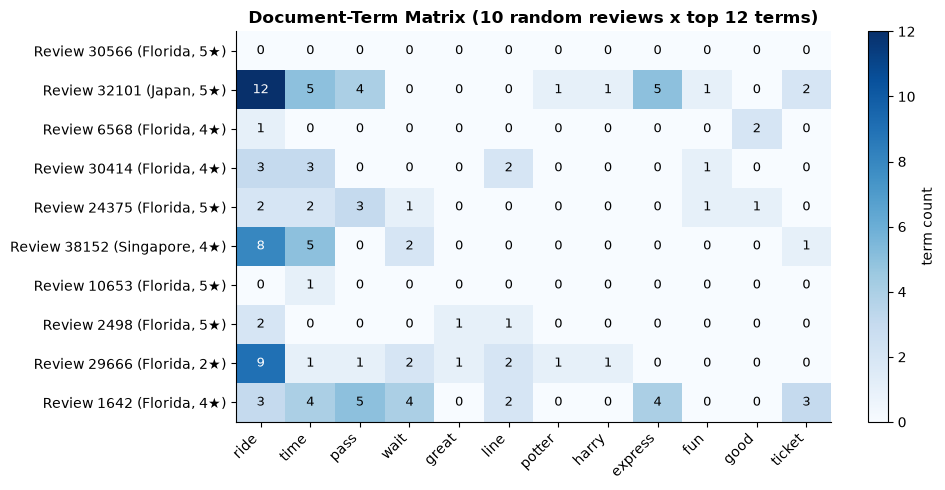

In [17]:
# Step 5. Document-Term Matrix (Bag of Words) for the whole corpus
cv = CountVectorizer(min_df=5)                 # keep words used in at least 5 reviews
dtm = cv.fit_transform(df["clean_text"])       # sparse matrix: rows = reviews, columns = words
vocab_all = cv.get_feature_names_out()
print("DTM shape (reviews x words):", dtm.shape)
print(f"Non-zero cells: {dtm.nnz:,} ({dtm.nnz / (dtm.shape[0] * dtm.shape[1]) * 100:.2f}% of the matrix)")

# Total count of each word across all reviews
word_totals = pd.Series(np.asarray(dtm.sum(axis=0)).ravel(), index=vocab_all).sort_values(ascending=False)
display(word_totals.head(15).rename("total count").to_frame().T)

# Heatmap of a small slice: 10 reviews x 12 most frequent words
top12 = word_totals.index[:12]
slice_ids = df.sample(10, random_state=3).index
sample = pd.DataFrame(dtm[slice_ids][:, [cv.vocabulary_[w] for w in top12]].toarray(),
                      columns=top12,
                      index=[f"Review {i} ({df.loc[i, 'branch']}, {int(df.loc[i, 'rating'])}★)" for i in slice_ids])

plt.figure(figsize=(10, 5))
plt.imshow(sample, cmap="Blues", aspect="auto")
plt.xticks(range(len(top12)), top12, rotation=45, ha="right")
plt.yticks(range(len(sample)), sample.index)
for i in range(sample.shape[0]):
    for j in range(sample.shape[1]):
        v = sample.iloc[i, j]
        plt.text(j, i, v, ha="center", va="center", fontsize=9, color="white" if v > sample.values.max() / 2 else "black")
plt.colorbar(label="term count")
plt.title("Document-Term Matrix (10 random reviews x top 12 terms)")
plt.tight_layout()
plt.show()

**Notes:**
- The full DTM has **50,859 rows (reviews) and 8,489 columns (words used in at least 5 reviews)**. Only 0.41% of the cells are non-zero, so it is stored as a sparse matrix. Most reviews use only a few dozen of the 8,489 words.
- The heatmap shows this: most cells are 0. Only two reviews (32101 from Japan and 1642 from Florida) mention "express" and "pass" together, and both are about buying Express Passes.
- The most used word overall is "ride" (102,192 times), far ahead of "time" (40,609). Raw counts like this favor words that every review uses, which is why TF-IDF is used next.

### 4.2 TF-IDF and Top Terms

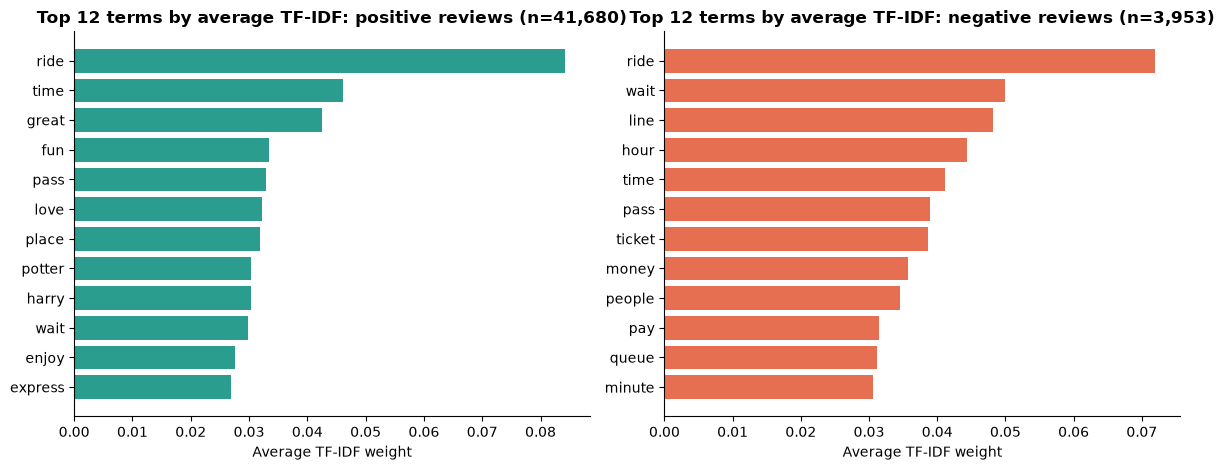

,positive,negative
0,ride (0.084),ride (0.072)
1,time (0.046),wait (0.050)
2,great (0.042),line (0.048)
3,fun (0.033),hour (0.044)
4,pass (0.033),time (0.041)
5,love (0.032),pass (0.039)
6,place (0.032),ticket (0.039)
7,potter (0.030),money (0.036)
8,harry (0.030),people (0.035)
9,wait (0.030),pay (0.031)


In [18]:
# Step 6. TF-IDF for every review
tfidf = TfidfVectorizer(min_df=5)
X = tfidf.fit_transform(df["clean_text"])
terms = tfidf.get_feature_names_out()

# Top terms = highest average TF-IDF across reviews, for each sentiment group
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
top_terms = {}
for ax, grp in zip(axes, ["positive", "negative"]):
    mask = (df["sentiment"] == grp).values
    mean_w = pd.Series(np.asarray(X[mask].mean(axis=0)).ravel(), index=terms).sort_values(ascending=False)
    top_terms[grp] = mean_w.head(12)
    ax.barh(mean_w.index[:12][::-1], mean_w.values[:12][::-1], color=SENT_COLORS[grp])
    ax.set_title(f"Top 12 terms by average TF-IDF: {grp} reviews (n={mask.sum():,})")
    ax.set_xlabel("Average TF-IDF weight")
plt.tight_layout()
plt.show()
display(pd.DataFrame({g: [f"{w} ({v:.3f})" for w, v in s.items()] for g, s in top_terms.items()}))

In [19]:
# Explaining one TF-IDF value: the top-weighted word in one negative Singapore review
example_id = df[(df["branch"] == "Singapore") & (df["sentiment"] == "negative") &
                (df["tokens"].apply(lambda t: t.count("express") >= 2)) &
                (df["tokens"].str.len().between(40, 70))].index[0]
row = X[example_id].toarray().ravel()
word = terms[row.argmax()]                 # the word with the highest TF-IDF in this review
col = tfidf.vocabulary_[word]
toks = df.loc[example_id, "tokens"]

n_docs = X.shape[0]
docs_with_term = int((X[:, col] > 0).sum())
idf = tfidf.idf_[col]

print("Review text:\n", df.loc[example_id, "review_text"][:500], "...\n")
print(f"Word explained: '{word}'")
print(f"Tokens in this review: {len(toks)} | times '{word}' appears: {toks.count(word)}")
print(f"Reviews containing '{word}': {docs_with_term:,} of {n_docs:,} ({docs_with_term / n_docs * 100:.2f}%)")
print(f"IDF = ln((1 + {n_docs}) / (1 + {docs_with_term})) + 1 = {idf:.3f}")
for w in ["ride", "express", "queue"]:
    c = tfidf.vocabulary_[w]
    print(f"For comparison, '{w}': appears {toks.count(w)}x here, in {int((X[:, c] > 0).sum()):,} reviews, "
          f"IDF = {tfidf.idf_[c]:.3f}, TF-IDF here = {row[c]:.3f}")
print(f"Final TF-IDF of '{word}' in this review (after L2 normalization) = {row[col]:.3f}")
top5 = pd.Series(row, index=terms).sort_values(ascending=False).head(5).round(3)
print("\nHighest TF-IDF words in this review:")
display(top5.to_frame("tf-idf").T)

Review text:
 It was supposed to be a place of fun. However, during the covid19. With the cut down of capacity, the park just tried to maximize their profit at the expense of customer experience. So many food and beverage outlets are closed leading to main f&b outlet to be immensely queued up. Normal snack and drink requires around 30mins queue. I suspected they also kept selling express pass without any capacity control. Leading express queue wait approximately 60-90mins for all rides. The experience is utte ...

Word explained: 'capacity'
Tokens in this review: 43 | times 'capacity' appears: 2
Reviews containing 'capacity': 221 of 50,859 (0.43%)
IDF = ln((1 + 50859) / (1 + 221)) + 1 = 6.434
For comparison, 'ride': appears 1x here, in 36,614 reviews, IDF = 1.329, TF-IDF here = 0.035
For comparison, 'express': appears 2x here, in 11,849 reviews, IDF = 2.457, TF-IDF here = 0.130
For comparison, 'queue': appears 3x here, in 9,095 reviews, IDF = 2.721, TF-IDF here = 0.216
Final TF-IDF of 

,capacity,lead,outlet,queue,utterly
tf-idf,0.34,0.328,0.312,0.216,0.21


**Top terms:**
- **Positive reviews:** ride, time, great, fun, pass, love, place, potter, harry, wait, enjoy, express. These are about the experience (fun, love, great) and the big attractions (Harry Potter).
- **Negative reviews:** ride, wait, line, hour, time, pass, ticket, money, people, pay, queue, minute. Almost every top word is about **time** (wait, line, hour, queue, minute) or **money** (ticket, money, pay). "Harry Potter" drops out of the top 12, and "people" (crowds) comes in.
- "wait" has an average TF-IDF of 0.050 in negative reviews vs 0.030 in positive ones, so waiting carries more weight in bad reviews even though happy visitors mention it too.

**One TF-IDF value explained in my own words:**
In the negative Singapore review above (written during COVID), the word **"capacity" has a TF-IDF of 0.340**, the highest of any word in that review.

- **TF (term frequency):** "capacity" appears 2 times in this review's 43 tokens.
- **IDF (inverse document frequency):** only 221 of the 50,859 reviews (0.43%) use "capacity", so it is a rare word. Its IDF is ln(50,860 / 222) + 1 = **6.434**.
- **Multiply and scale:** TF x IDF is then scaled so the whole review's vector has a length of 1. That is why the final value is 0.340 and not 12.9.

In my own words: **0.340 means "capacity" is the word that best describes what makes this review different from the other 50,000.** Compare it to "queue", which appears 3 times (more than "capacity") but only gets 0.216 because 9,095 reviews also mention queues. "ride" appears once and gets just 0.035 because 72% of all reviews use it. So TF-IDF tells us this review is not a normal "long queue" complaint. It is about the park **reducing capacity during COVID and still selling Express Passes**. I use the same idea in Visualization 4 to find words that are special to each branch's complaints.

## 5–6. Visualize and Interpret

Requirements: at least 5 visualizations across at least 4 categories (size, position, structure, time, collections, sentiment/topic). At least one compares groups and at least one shows context (KWIC or word tree).

| # | Visualization | Category | Compares groups? | Shows context? |
|---|---|---|---|---|
| 1 | Word clouds: positive vs negative reviews | Size | Yes (sentiment) | No |
| 2 | Complaint themes in negative vs positive reviews | Sentiment/topic | Yes (sentiment) | No |
| 3 | Complaint themes by branch (heatmap) | Collections | Yes (branch) | No |
| 4 | Most distinctive TF-IDF terms in each branch's negative reviews | Sentiment/topic | Yes (branch) | No |
| 5 | Negative reviews and complaint themes over time | Time | Yes (branch) | No |
| 6 | Keyword-in-Context (KWIC) for each branch's top issue | Context | Yes (branch) | **Yes** |
| 7 | Word co-occurrence network of negative reviews | Structure / position | No | Partly (word pairs) |

Categories covered: **size, sentiment/topic, collections, time, structure/position** (5 of 6).

**Complaint themes (used in Visualizations 2, 3 and 5).** To answer "what makes a bad experience", I grouped related words into 9 themes. A review counts toward a theme if it contains at least one of the theme's words (after lemmatization). The words were chosen from the top terms in Section 4 and checked with KWIC in Visualization 6.

In [20]:
# Theme dictionary (keyword-based topics)
THEMES = {
    "Long waits & queues": {"wait", "queue", "line", "hour", "minute", "min"},
    "Express Pass":        {"express"},
    "Crowds":              {"crowd", "crowded", "packed", "busy", "overcrowded"},
    "Price & value":       {"expensive", "price", "overprice", "overpriced", "money", "cost", "refund", "worth", "pricey"},
    "Rides closed/broken": {"close", "closed", "broken", "break", "breakdown", "maintenance", "shut", "refurbishment", "malfunction"},
    "Staff & service":     {"staff", "rude", "employee", "service", "manager", "attitude", "unhelpful"},
    "Food":                {"food", "restaurant", "meal", "eat", "drink"},
    "Weather & heat":      {"hot", "heat", "rain", "weather", "humid", "sun"},
    "COVID rules":         {"mask", "covid", "pandemic", "distancing", "virus", "coronavirus", "quarantine"},
}
token_sets = df["tokens"].apply(set)
for theme, words in THEMES.items():
    df[theme] = token_sets.apply(lambda s: bool(words & s))
THEME_NAMES = list(THEMES)
neg = df[df["sentiment"] == "negative"]
pos = df[df["sentiment"] == "positive"]
print("Negative reviews:", len(neg), "| Positive reviews:", len(pos))
display((neg.groupby("branch")[THEME_NAMES].mean() * 100).round(1).T)

Negative reviews: 3953 | Positive reviews: 41680


branch,Florida,Japan,Singapore
Long waits & queues,70.4,87.7,79.4
Express Pass,23.9,32.3,30.2
Crowds,17.6,31.2,19.5
Price & value,61.5,53.2,60.8
Rides closed/broken,25.6,18.9,27.3
Staff & service,36.9,21.9,28.0
Food,31.6,32.9,28.6
Weather & heat,10.6,11.5,22.1
COVID rules,3.3,0.3,1.4


### Visualization 1: Word Clouds of Positive vs Negative Reviews
**Category:**  Size (word size = frequency), comparing sentiment groups

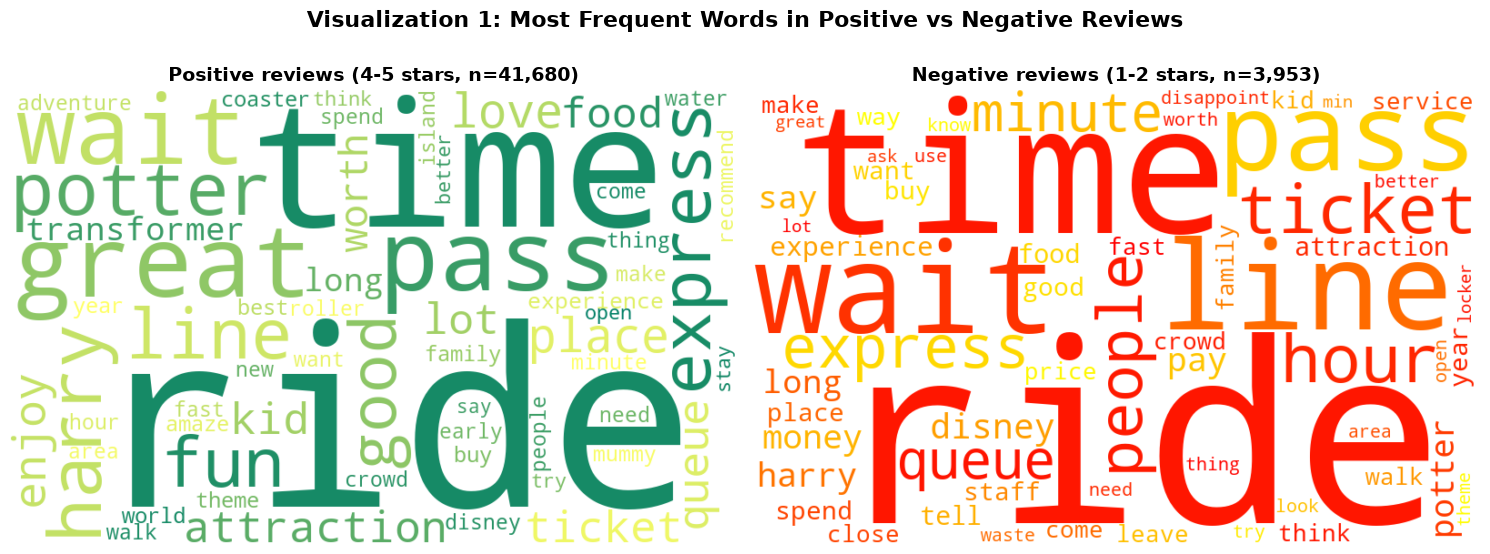

,positive %,negative %
ride,4.72,3.52
wait,1.07,1.50
line,0.86,1.42
queue,0.66,0.75
money,0.20,0.65
staff,0.23,0.45
tell,0.09,0.51
fun,0.84,0.21
great,1.17,0.27


In [21]:
# Visualization 1: word clouds, positive vs negative (SIZE)
pos_freq = Counter(t for ts in pos["tokens"] for t in ts)
neg_freq = Counter(t for ts in neg["tokens"] for t in ts)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, freq, title, cmap in [
        (axes[0], pos_freq, f"Positive reviews (4-5 stars, n={len(pos):,})", "summer"),
        (axes[1], neg_freq, f"Negative reviews (1-2 stars, n={len(neg):,})", "autumn")]:
    wc = WordCloud(width=800, height=500, background_color="white", colormap=cmap,
                   max_words=60, random_state=42).generate_from_frequencies(freq)
    ax.imshow(wc, interpolation="bilinear")
    ax.set_title(title, fontsize=14)
    ax.axis("off")
fig.suptitle("Visualization 1: Most Frequent Words in Positive vs Negative Reviews", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

# numbers behind the clouds (share of all tokens in each group)
compare = pd.DataFrame({
    "positive %": {w: pos_freq[w] / sum(pos_freq.values()) * 100 for w in ["ride", "wait", "line", "queue", "money", "staff", "tell", "fun", "great"]},
    "negative %": {w: neg_freq[w] / sum(neg_freq.values()) * 100 for w in ["ride", "wait", "line", "queue", "money", "staff", "tell", "fun", "great"]},
}).round(2)
display(compare)

**Interpretation:**  
- *What it shows:*  Two word clouds of the most frequent words (after preprocessing) in positive (4-5★) and negative (1-2★) reviews. Bigger words appear more often in that group.
- *Insight (with numbers):*  "ride", "time", and "pass" are big in both clouds, but the rest differ. Positive reviews are led by "great" (1.17% of all tokens) and "fun" (0.84%), while negative reviews are led by "wait" (1.50%), "line" (1.42%), and "money" (0.65%, about 3x its share in positive reviews). Words like "tell" (0.51% vs 0.09%) suggest unhappy visitors often describe what staff told them.
- *Limitation:*  Word clouds show size but not exact values, and longer words look bigger than they are. "ride" dominates both clouds, so the cloud alone does not show what is different. The table under the chart was added to give the exact numbers.

### Visualization 2: Complaint Themes in Negative vs Positive Reviews
**Category:**  Sentiment/topic, comparing sentiment groups

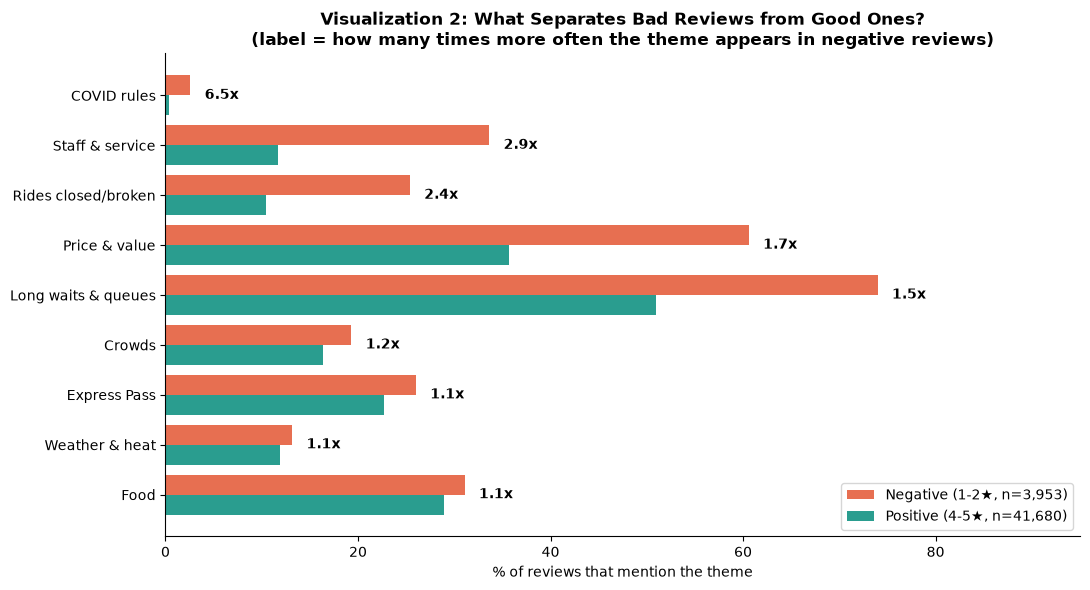

,negative,positive,ratio (neg / pos)
Food,31.07,28.96,1.07
Weather & heat,13.15,11.93,1.10
Express Pass,26.01,22.70,1.15
Crowds,19.30,16.31,1.18
Long waits & queues,73.97,50.94,1.45
Price & value,60.59,35.66,1.70
Rides closed/broken,25.37,10.45,2.43
Staff & service,33.62,11.64,2.89
COVID rules,2.58,0.40,6.52


In [22]:
# Visualization 2: which themes separate negative from positive reviews? (SENTIMENT / TOPIC)
theme_cmp = pd.DataFrame({
    "negative": neg[THEME_NAMES].mean() * 100,
    "positive": pos[THEME_NAMES].mean() * 100,
})
theme_cmp["ratio (neg / pos)"] = theme_cmp["negative"] / theme_cmp["positive"]
theme_cmp = theme_cmp.sort_values("ratio (neg / pos)")

fig, ax = plt.subplots(figsize=(11, 6))
y = np.arange(len(theme_cmp))
ax.barh(y + 0.2, theme_cmp["negative"], height=0.4, color=SENT_COLORS["negative"], label=f"Negative (1-2★, n={len(neg):,})")
ax.barh(y - 0.2, theme_cmp["positive"], height=0.4, color=SENT_COLORS["positive"], label=f"Positive (4-5★, n={len(pos):,})")
for i, (n, p, r) in enumerate(theme_cmp.values):
    ax.text(max(n, p) + 1.5, i, f"{r:.1f}x", va="center", fontsize=10, fontweight="bold")
ax.set_yticks(y)
ax.set_yticklabels(theme_cmp.index)
ax.set_xlabel("% of reviews that mention the theme")
ax.set_xlim(0, 95)
ax.set_title("Visualization 2: What Separates Bad Reviews from Good Ones?\n(label = how many times more often the theme appears in negative reviews)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()
display(theme_cmp.round(2))

**Interpretation:**  
- *What it shows:*  For each of the 9 complaint themes, the % of negative reviews and the % of positive reviews that mention it. The label is the ratio (how many times more common the theme is in negative reviews). Themes are sorted by that ratio.
- *Insight (with numbers):*  Long waits are mentioned the most (74.0% of negative reviews), but they are also in 50.9% of positive reviews, a ratio of only 1.5x. The themes that really **separate** bad reviews are **Staff & service (33.6% vs 11.6%, 2.9x)** and **Rides closed/broken (25.4% vs 10.5%, 2.4x)**. COVID rules have the highest ratio (6.5x) but appear in only 2.6% of negative reviews. So the main answer to "what makes a bad experience" is not just waiting. It is waiting **plus** bad staff interactions and rides that are closed.
- *Limitation:*  Theme matching is keyword-based, so it cannot tell "long wait" from "short wait" or "not crowded" from "crowded" (see Section 3). Also, a review can mention a theme without that theme being the reason for the low rating.

### Visualization 3: Complaint Themes by Branch (Heatmap)
**Category:**  Collections (comparing the three branches' groups of negative reviews)

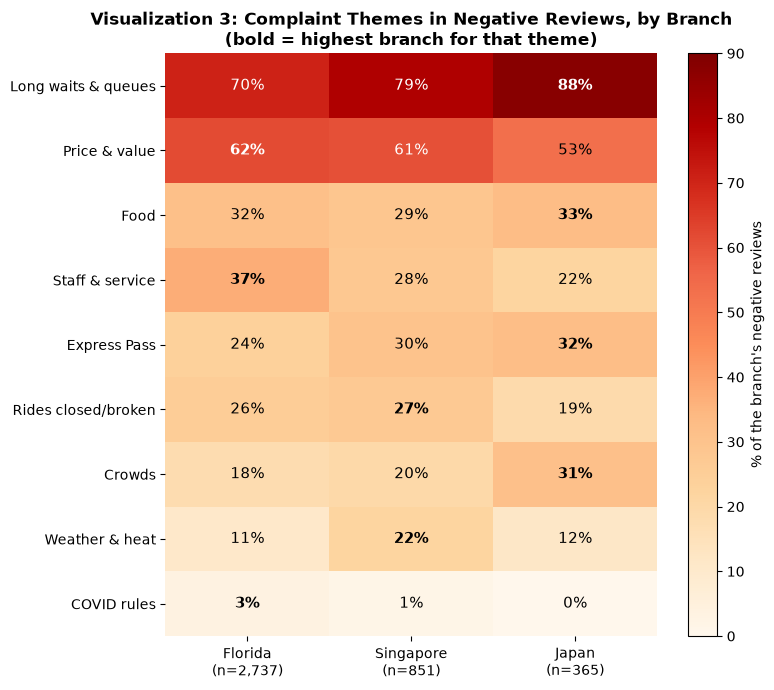

In [23]:
# Visualization 3: what does each park get complained about? (COLLECTIONS / compare groups)
heat = (neg.groupby("branch")[THEME_NAMES].mean() * 100).loc[BRANCHES].T
heat = heat.loc[heat.mean(axis=1).sort_values(ascending=False).index]
n_neg = neg["branch"].value_counts()

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(heat.values, cmap="OrRd", aspect="auto", vmin=0, vmax=90)
ax.set_xticks(range(3))
ax.set_xticklabels([f"{b}\n(n={n_neg[b]:,})" for b in BRANCHES])
ax.set_yticks(range(len(heat)))
ax.set_yticklabels(heat.index)
for i in range(heat.shape[0]):
    row_max = heat.values[i].max()
    for j in range(heat.shape[1]):
        v = heat.values[i, j]
        ax.text(j, i, f"{v:.0f}%", ha="center", va="center", fontsize=11,
                fontweight="bold" if v == row_max else "normal", color="white" if v > 55 else "black")
plt.colorbar(im, label="% of the branch's negative reviews")
ax.set_title("Visualization 3: Complaint Themes in Negative Reviews, by Branch\n(bold = highest branch for that theme)")
ax.spines[:].set_visible(False)
plt.tight_layout()
plt.show()

**Interpretation:**  
- *What it shows:*  A heatmap of the % of each branch's negative reviews that mention each theme. Darker = more common. The highest branch for each theme is in bold. Percentages are used because the branches have very different sizes (2,737 vs 851 vs 365 negative reviews).
- *Insight (with numbers):*  Each park has a different main problem. **Japan** has the most queue complaints (88% of its negative reviews), plus the most Crowds (31%) and Express Pass (32%) mentions. **Florida** leads in Staff & service (37%, vs 22% in Japan) and Price & value (62%). **Singapore** leads in Rides closed/broken (27%) and has twice the Weather & heat complaints of the others (22% vs 11-12%), which fits an outdoor park in a hot, humid country.
- *Limitation:*  Japan has only 365 negative reviews, so a difference of a few points (for example Food: 33% vs 32%) is within normal variation. Only the large gaps should be used for decisions.

### Visualization 4: Most Distinctive TF-IDF Terms in Each Branch's Negative Reviews
**Category:**  Sentiment/topic (TF-IDF), comparing branches

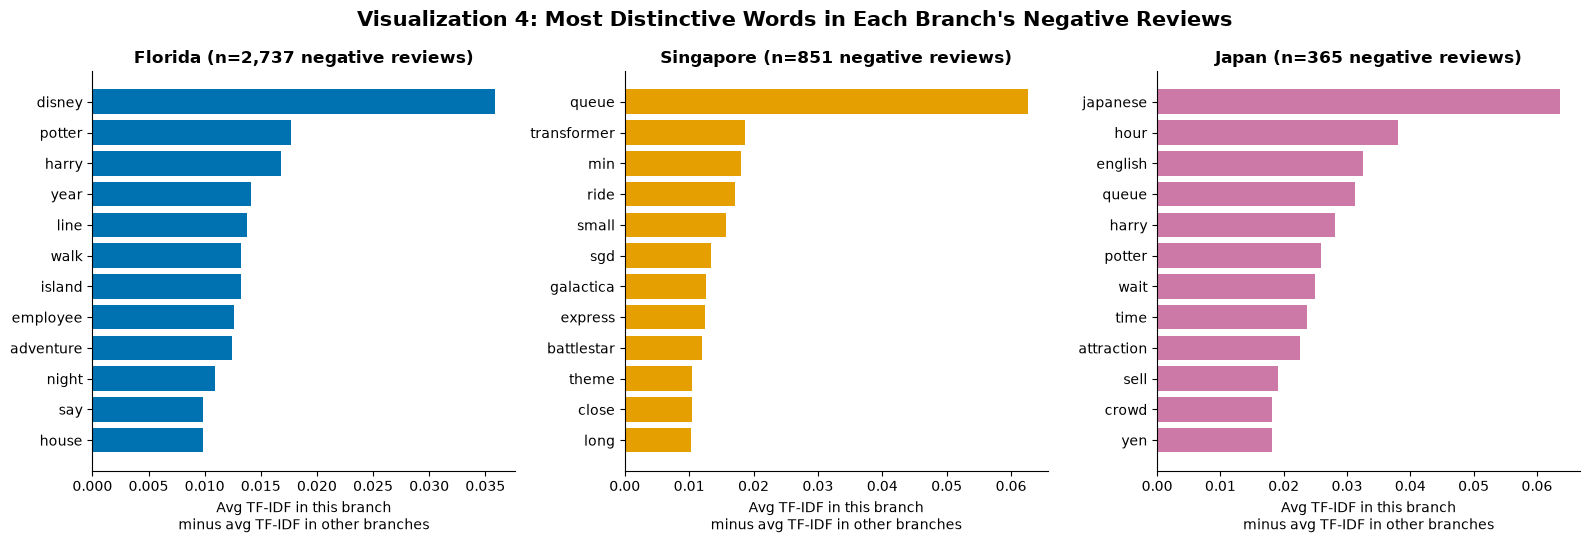

,% of negative reviews,% of positive reviews
Japan: 'english',16.4,9.1
Japan: 'japanese',26.8,23.9
Singapore: 'queue',45.0,27.6
Singapore: 'close',20.2,7.6
Florida: 'disney',32.2,15.8
Florida: 'employee',9.7,1.9


In [24]:
# Visualization 4: words that weigh more in one branch's complaints than in the other two (SENTIMENT/TOPIC)
tf_neg = TfidfVectorizer(min_df=20)
Xn = tf_neg.fit_transform(neg["clean_text"])
neg_terms = tf_neg.get_feature_names_out()

fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
distinct = {}
for ax, b in zip(axes, BRANCHES):
    m = (neg["branch"] == b).values
    this_branch = np.asarray(Xn[m].mean(axis=0)).ravel()
    others = np.asarray(Xn[~m].mean(axis=0)).ravel()
    diff = pd.Series(this_branch - others, index=neg_terms).sort_values(ascending=False).head(12)
    distinct[b] = diff
    ax.barh(diff.index[::-1], diff.values[::-1], color=BRANCH_COLORS[b])
    ax.set_title(f"{b} (n={m.sum():,} negative reviews)")
    ax.set_xlabel("Avg TF-IDF in this branch\nminus avg TF-IDF in other branches")
fig.suptitle("Visualization 4: Most Distinctive Words in Each Branch's Negative Reviews",
             fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

# How often do key words show up in negative vs positive reviews of each branch?
check = {}
for b, w in [("Japan", "english"), ("Japan", "japanese"), ("Singapore", "queue"), ("Singapore", "close"),
             ("Florida", "disney"), ("Florida", "employee")]:
    sub = df[df["branch"] == b]
    check[f"{b}: '{w}'"] = {s: round(sub[sub["sentiment"] == s]["tokens"].apply(lambda t: w in t).mean() * 100, 1)
                            for s in ["negative", "positive"]}
display(pd.DataFrame(check).T.rename(columns=lambda c: f"% of {c} reviews"))

**Interpretation:**  
- *What it shows:*  For each branch, the 12 words whose average TF-IDF in that branch's negative reviews is highest compared to the other two branches. A longer bar means the word is more special to that park's complaints.
- *Insight (with numbers):*  **Japan:** "japanese" and "english" are its 1st and 3rd most distinctive words. "english" is in 16.4% of Japan's negative reviews but only 9.1% of its positive ones, so the language barrier is a real complaint. **Singapore:** "queue" stands out by far (45.0% of negative reviews vs 27.6% of positive), followed by ride names (Transformers, Battlestar Galactica) and "close" (20.2% vs 7.6%), so specific rides being shut is a key issue. **Florida:** "disney" is in 32.2% of negative reviews vs 15.8% of positive, so unhappy visitors compare it to Disney World. "employee" is in 9.7% vs 1.9% (5x).
- *Limitation:*  Some distinctive words are just local names ("sgd", "yen", ride names) or the word for queue in local English (Singapore says "queue", Florida says "line"). These reflect how people write in each place, not a different problem, so I checked the key words against positive reviews (table) and KWIC (Visualization 6).

### Visualization 5: Negative Reviews and Complaint Themes Over Time
**Category:**  Time

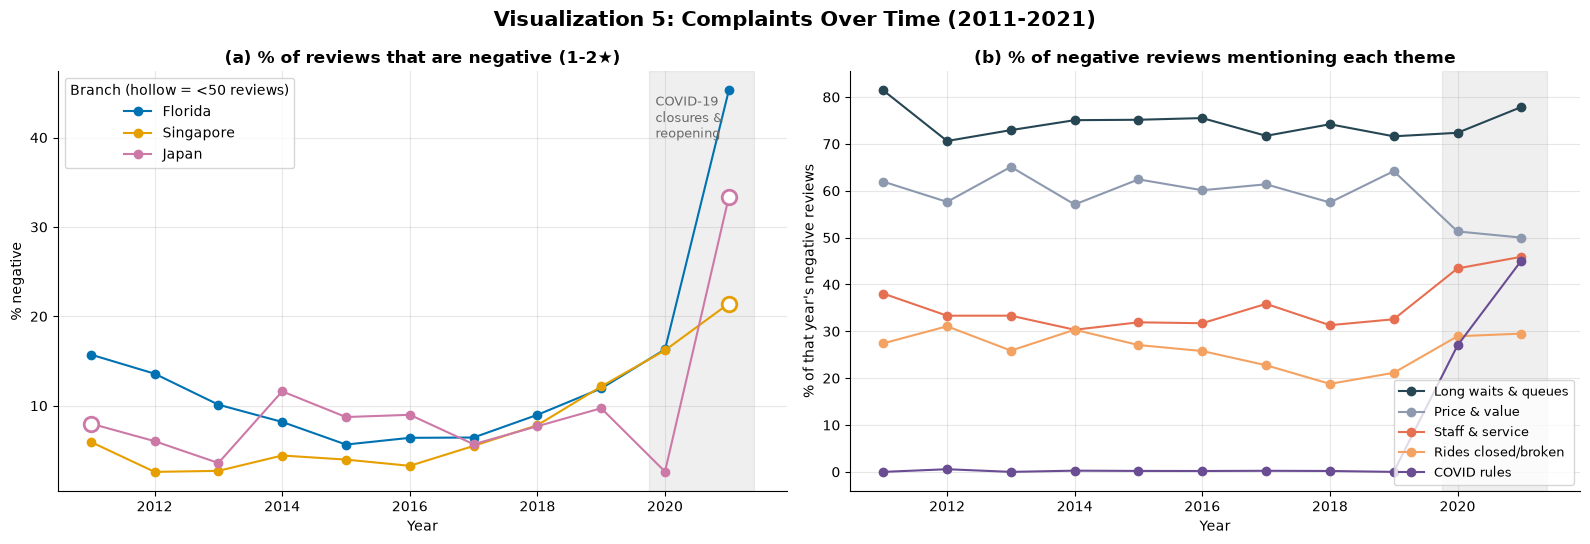

,Florida,Japan,Singapore
period,,,
Before COVID,2548,363,820
COVID period (Mar 2020+),189,2,31


period,Before COVID,COVID period (Mar 2020+)
Long waits & queues,74.0,73.4
Express Pass,26.6,15.8
Crowds,19.4,18.5
Price & value,61.2,50.0
Rides closed/broken,25.2,27.5
Staff & service,32.8,47.3
Food,30.8,36.0
Weather & heat,13.2,12.2
COVID rules,0.2,43.2


In [25]:
# Visualization 5: how did complaints change over time? (TIME)
years = range(2011, 2022)
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# (a) share of reviews that are negative, per branch per year
ax = axes[0]
for b in BRANCHES:
    sub = df[df["branch"] == b]
    share = sub.groupby("year")["sentiment"].apply(lambda s: (s == "negative").mean() * 100).reindex(years)
    counts = sub.groupby("year").size().reindex(years).fillna(0)
    ax.plot(share.index, share.values, marker="o", color=BRANCH_COLORS[b], label=b)
    small = counts < 50          # hollow markers = fewer than 50 reviews that year
    ax.scatter(share.index[small], share.values[small], s=110, facecolors="white",
               edgecolors=BRANCH_COLORS[b], zorder=3, linewidths=2)
ax.axvspan(2019.75, 2021.4, color="grey", alpha=0.12)
ax.text(2019.85, 40, "COVID-19\nclosures &\nreopening", fontsize=9, color="dimgray")
ax.set_title("(a) % of reviews that are negative (1-2★)")
ax.set_xlabel("Year")
ax.set_ylabel("% negative")
ax.legend(title="Branch (hollow = <50 reviews)")
ax.grid(alpha=0.3)

# (b) share of negative reviews mentioning each theme, all branches
ax = axes[1]
watch = {"Long waits & queues": "#264653", "Price & value": "#8d99ae",
         "Staff & service": "#e76f51", "Rides closed/broken": "#f4a261", "COVID rules": "#6a4c93"}
for theme, color in watch.items():
    trend = neg.groupby("year")[theme].mean().reindex(years) * 100
    ax.plot(trend.index, trend.values, marker="o", label=theme, color=color)
ax.axvspan(2019.75, 2021.4, color="grey", alpha=0.12)
ax.set_title("(b) % of negative reviews mentioning each theme")
ax.set_xlabel("Year")
ax.set_ylabel("% of that year's negative reviews")
ax.legend(fontsize=9)
ax.grid(alpha=0.3)

fig.suptitle("Visualization 5: Complaints Over Time (2011-2021)", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

# Before vs during COVID (cut-off: March 1, 2020)
neg_period = neg.assign(period=np.where(neg["written_date"] >= "2020-03-01", "COVID period (Mar 2020+)", "Before COVID"))
display(neg_period.groupby(["period", "branch"]).size().unstack().rename_axis(None, axis=1))
display((neg_period.groupby("period")[THEME_NAMES].mean() * 100).round(1).T)

**Interpretation:**  
- *What it shows:*  (a) The % of each branch's reviews that are negative, per year from 2011 to 2021. Hollow circles mark years with fewer than 50 reviews. (b) Among all negative reviews in each year, the % that mention five key themes. The grey band marks the COVID-19 closures and reopening (2020-2021).
- *Insight (with numbers):*  Negative reviews were already **rising before COVID**: Florida went from 5.7% (2015) to 11.9% (2019), and Singapore from 3.3% (2016) to 12.2% (2019). In the COVID period it jumped to **45.3% for Florida in 2021**. The complaints also changed: comparing before vs after March 2020, Staff & service went from 32.8% to 47.3% of negative reviews and COVID rules from 0.2% to 43.2%, while Express Pass (26.6% to 15.8%) and Price (61.2% to 50.0%) went down. Queue complaints stayed at about 74% in both periods.
- *Limitation:*  The COVID period has very few reviews (189 negative for Florida, 31 for Singapore, only 2 for Japan), and 2021 only covers January to May. The Japan and Singapore 2021 points are based on 3 and 28 reviews, so the COVID findings mainly describe Florida.

### Visualization 6: Keyword-in-Context (KWIC) for Each Branch's Top Issue
**Category:**  Context (KWIC), comparing branches

In [26]:
# Visualization 6: KWIC -> read the words around each branch's distinctive complaint word
def kwic(texts, keyword, width=45, max_lines=8):
    """Print up to max_lines concordance lines for a keyword."""
    shown = 0
    for text in texts:
        text = text.replace("\n", " ")
        for m in re.finditer(rf"\b{keyword}\b", text, flags=re.I):
            left = text[max(0, m.start() - width):m.start()]
            right = text[m.end():m.end() + width]
            print(f"{left:>{width}} [{m.group().upper()}] {right}")
            shown += 1
            if shown >= max_lines:
                return
            break      # one line per review so no single review dominates

for branch, keyword in [("Japan", "english"), ("Singapore", "maintenance"), ("Florida", "employees")]:
    texts = neg[neg["branch"] == branch]["review_text"].sample(frac=1, random_state=1)   # random order
    hits = texts.str.contains(rf"\b{keyword}\b", case=False).sum()
    print(f"\n=== {branch}: '{keyword}' (in {hits} of {len(texts)} negative reviews) ===")
    kwic(texts, keyword)


=== Japan: 'english' (in 60 of 365 negative reviews) ===
r issue : NOT MANY SHOP ASSISTANTS CAN SPEAK  [ENGLISH] .  Rather disappointing visit.  Food also not
 since!! Not very international friendly. No  [ENGLISH]  subtitles at all, can't follow story lines t
e ticket, so I wouldn't bother with this. No  [ENGLISH]  commentaries in any rides, so trip around Ja
press passes. But the clerk didn't speak any  [ENGLISH] . So no luck for us. Next time I just won't g
ally thought that they will provide at least  [ENGLISH]  subtitles for the 3D/4D shows, but everythin
s one. Hardly anyone at the park understands  [ENGLISH] , every time I complained they gave a sticker
 and Kurt Russell speak in Japanese... haha   [ENGLISH]  subtitles in a tiny corner do no harm to any
nly. How difficult is it to add Mandarin and  [ENGLISH]  subtitles? The Backdraft show was the worst 

=== Singapore: 'maintenance' (in 26 of 851 negative reviews) ===
 from either from wear and tear or just poor  [MAINTENANCE] 

**Interpretation:**  
- *What it shows:*  Keyword-in-Context (KWIC) lines for one distinctive complaint word per branch, taken from negative reviews in random order (one line per review). The keyword is in [BRACKETS] with about 45 characters on each side.
- *Insight (with numbers):*  The context confirms what the earlier charts suggested. In **Japan**, "english" (in 60 of 365 negative reviews) is used for missing English subtitles in shows and staff who cannot speak English (for example "No ENGLISH subtitles at all, can't follow story lines"). In **Singapore**, "maintenance" (26 of 851) is about specific rides closing (Mummy, Transformers, Jurassic Park) on the day people paid full price. In **Florida**, "employees" (196 of 2,737) is mostly about rude or disengaged staff.
- *Limitation:*  KWIC shows only 8 lines per word, so it is evidence of what the word means, not a count. A reader could pick lines that fit their story, which is why the lines are shown in a fixed random order (random_state=1) and not hand-picked.

### Visualization 7: Word Co-occurrence Network of Negative Reviews
**Category:**  Structure / position

,0,1,2,3,4,5,6,7,8,9,10,11
bigram,harry potter,express pass,wait time,fast pass,wait line,island adventure,roller coaster,customer service,wait hour,year old,long line,waste time
count,1564,1286,782,642,456,418,411,339,336,314,294,271


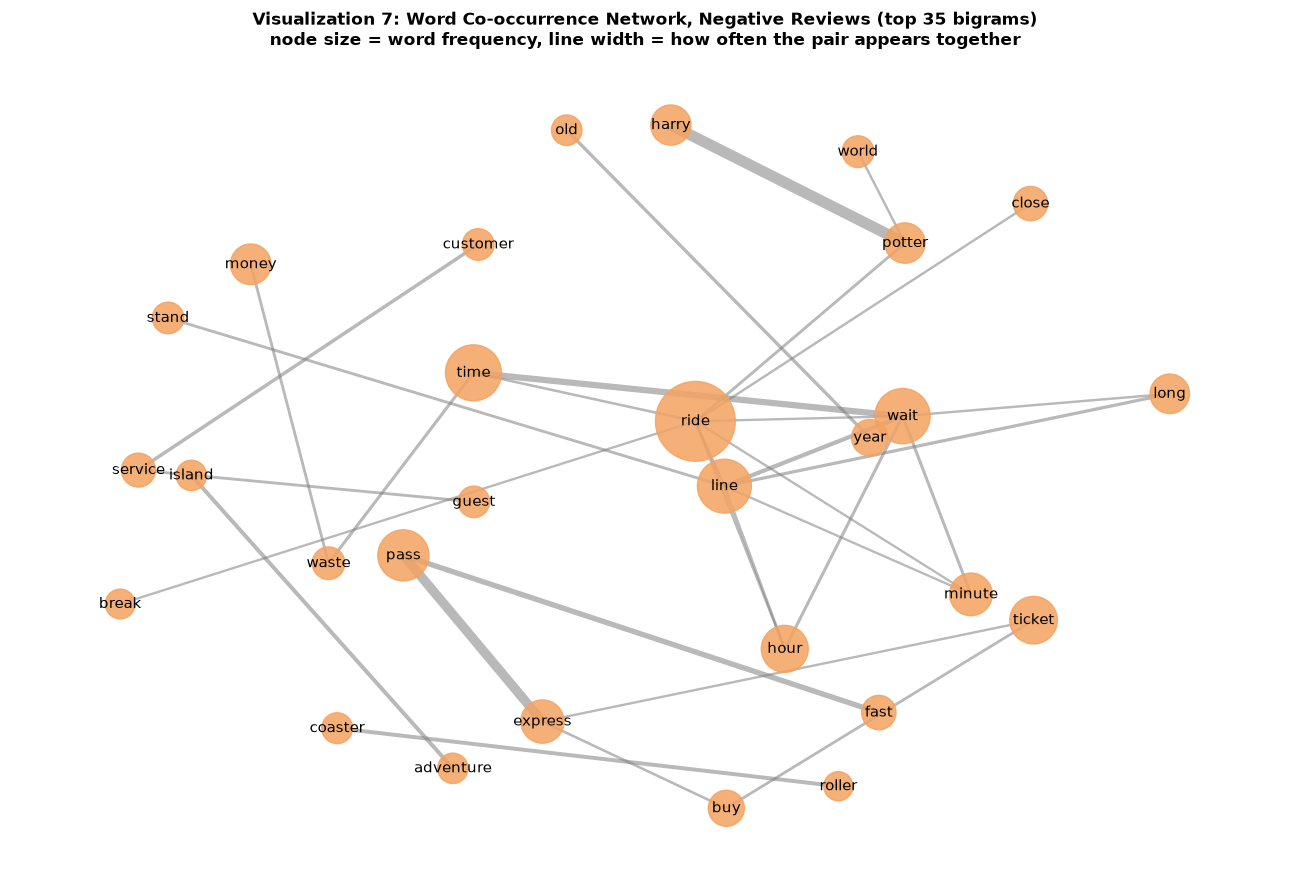

In [27]:
# Visualization 7: which words appear next to each other in complaints? (STRUCTURE / POSITION)
bigrams = Counter((a, b) for tokens in neg["tokens"] for a, b in zip(tokens, tokens[1:]) if a != b)
top_bigrams = bigrams.most_common(35)
display(pd.DataFrame([(f"{a} {b}", n) for (a, b), n in top_bigrams[:12]], columns=["bigram", "count"]).T)

G = nx.Graph()
for (a, b), n in top_bigrams:
    G.add_edge(a, b, weight=n)

pos_layout = nx.spring_layout(G, k=1.1, seed=42, weight=None)
max_w = max(n for _, n in top_bigrams)
plt.figure(figsize=(13, 9))
nx.draw_networkx_edges(G, pos_layout, alpha=0.55, edge_color="gray",
                       width=[1 + 7 * G[u][v]["weight"] / max_w for u, v in G.edges()])
nx.draw_networkx_nodes(G, pos_layout, node_color="#f4a261", alpha=0.85,
                       node_size=[300 + 3000 * neg_freq[n] / neg_freq.most_common(1)[0][1] for n in G.nodes()])
nx.draw_networkx_labels(G, pos_layout, font_size=11)
plt.title(f"Visualization 7: Word Co-occurrence Network, Negative Reviews (top 35 bigrams)\n"
          f"node size = word frequency, line width = how often the pair appears together", fontweight="bold")
plt.axis("off")
plt.tight_layout()
plt.show()

**Interpretation:**  
- *What it shows:*  A network of the 35 most common word pairs (bigrams) in negative reviews. Each circle is a word (bigger = more frequent) and each line connects two words that appear next to each other (thicker = more often).
- *Insight (with numbers):*  The biggest cluster is built around **ride, wait, line, time, hour, and minute**, showing that complaints about rides are mostly about the time spent waiting ("wait time" 782 times, "wait hour" 336, "long line" 294). A second cluster links **express, pass, fast, ticket, and buy** ("express pass" 1,286 times), so paying extra to skip lines is a big topic. Smaller separate pairs show other issues: "customer service" (339), "waste time" (271), and "waste money".
- *Limitation:*  Bigrams only connect words that were next to each other after stop words were removed, so "not worth the money" becomes "worth money" and the meaning flips. Some pairs are not complaints at all ("harry potter", "year old", "roller coaster"), so the network shows what people talk about, not only what they dislike.

## 7. Evaluate

My two most important visualizations are **Visualization 2** (it answers the main question: what drives a bad experience) and **Visualization 3** (it answers sub-question 1 and tells each park what to fix first).

### Most important visualization A: Visualization 2, Complaint Themes in Negative vs Positive Reviews

| Criterion | Answer |
|---|---|
| Interpretability | High. It is a simple paired bar chart with the % on one axis and theme names written out in plain words. Green vs orange matches positive vs negative across the whole notebook, and the "2.9x" labels give the main takeaway without needing to compare bar lengths. A reader needs one sentence of explanation: a theme counts if the review uses any of its keywords. |
| Faithfulness | Mostly faithful. The bars start at 0 and use the same scale, so lengths are not exaggerated, and percentages are used so the much larger positive group (41,680 vs 3,953) does not distort the comparison. The weak point is the keyword matching: negations are removed during preprocessing, so "not crowded" counts as a crowd mention. Because this error happens in both groups, the **ratio** is more faithful than the raw % for each group. |
| Trust | Moderate to high. The main finding (staff and closed rides separate bad reviews more than waiting does) holds for all three branches and is confirmed by KWIC lines. I would trust it to rank problems, but not to give exact numbers, because the keyword lists are my own choice and a different list would change the %s by a few points. The ratings are also self-selected TripAdvisor reviews, so they show what unhappy reviewers write about, not what all visitors feel. |

### Most important visualization B: Visualization 3, Complaint Themes by Branch (Heatmap)

| Criterion | Answer |
|---|---|
| Interpretability | High. Each cell shows its number, so the reader does not have to guess from color alone, and the bold cell in each row shows the "worst" park for that theme at a glance. Sample sizes are in the column labels. |
| Faithfulness | Faithful for the big differences. Using % of each branch's own negative reviews removes the size difference between Florida (2,737) and Japan (365). The color scale starts at 0 and is the same for every cell. However, color makes 70% and 79% look almost the same even though that gap is real, and it can make small gaps look important. |
| Trust | Moderate. Large gaps (Japan crowds 31% vs 18-20%, Singapore weather 22% vs 11-12%, Florida staff 37% vs 22-28%) are trustworthy and match the TF-IDF words and KWIC lines. Small gaps are not, especially for Japan, where 365 reviews means a few reviews can move a cell by 1-2 points. The Japan data is also English-only, so it mostly represents foreign tourists, which partly explains the language complaints. |

## 8. Report and Recommend

The full 3–5 page insight report is submitted separately. A summary is below.

### Executive Summary
Most reviews were positive. Long waits are the most common complaint, but what really separates bad visits from good ones is poor staff service and closed rides. Each park has its own main problem. Negative reviews were already rising before COVID.

### Key Findings
1. Staff and closed rides matter more than waiting. Staff complaints are 2.9x more common in negative reviews than in positive ones, and closed rides 2.4x. Waits are only 1.5x.
2. Each park’s main problem is different:
    * Japan: queues (in 88% of negative reviews), crowds, and the language barrier.
    * Singapore: closed rides and the heat.
    * Florida: staff (37% of negative reviews), plus visitors comparing it to Disney.
3. Complaints went up over time. Negative reviews were already growing from 2015 to 2019. During COVID, Florida reached 45% negative in 2021, and complaints shifted toward staff and COVID rules.

### Recommendations
1. Train staff on how they treat guests and enforce rules, starting with Florida. The goal is to bring staff complaints from 37% down to the 22 to 28% range of the other parks.
2. Tell guests which rides are closed before they buy tickets, and give a discount or return ticket when major rides are down. Singapore should also add shade and cooling in queue areas.
3. Make Universal Studios Japan easier for foreign visitors: English subtitles for shows, staff with basic English at the ticket and Express Pass counters, and live wait times in English.
4. Repeat this review analysis every quarter. This one also notes the data’s limits: reviews only go up to May 2021, they’re English only, and almost all the COVID-period reviews are from Florida.